[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_stormTracks_KKN_May2024_HID_doppler/blob/main/notebooks/07_damage_severity_vs_radar.ipynb)


# บทที่ 07 — พายุที่ทำความเสียหายต่างจากพายุอื่นอย่างไร: ระดับความเสียหาย × เรดาร์ × การสัมผัสภัย

บท 05 พบว่าเส้นทางพายุที่จับคู่กับรายงานความเสียหายมี "ลูกเห็บในคอลัมน์" มากกว่าเส้นทางอื่น และบท 06 พบว่าอำเภอที่มีรายงานไม่ได้มีพายุบ่อยกว่าอำเภออื่น บทนี้ยกระดับเป็น **การออกแบบงานวิจัยที่ตีพิมพ์ได้**: จัดระดับความเสียหายจากจำนวนบ้านเรือน (Weak / Moderate / Severe) รวมข้อมูลให้ถูกระดับ (อำเภอ → เหตุการณ์ → วัน) แล้วเปรียบเทียบคุณสมบัติเรดาร์ของพายุที่ทำความเสียหาย **แบบรวมและแยกระดับ** กับพายุในวันที่ไม่มีรายงาน โดยควบคุมระยะเรดาร์ การบังลำคลื่น และการสัมผัสภัย (ประชากร/สิ่งปลูกสร้าง GHSL) ทำซ้ำทั้ง Δt = 15, 10 และ 5 นาที

### คำถามวิจัย
| | คำถาม | สมมติฐาน |
|---|---|---|
| RQ1 | พายุที่ทำความเสียหาย (A) ต่างจากพายุวันเดียวกันที่ไม่ทำความเสียหาย (B) และพายุในวันที่ไม่มีรายงาน (C) อย่างไร | ต่างที่ความแรงเชิงไมโครฟิสิกส์ (ลูกเห็บ, KDP, แกน ≥45 dBZ) มากกว่าขนาด/อายุ |
| RQ2 | คุณสมบัติเรดาร์เพิ่มขึ้นเป็นขั้นตามระดับความเสียหายหรือไม่ (C ≤ B < Weak < Moderate < Severe) | มีความสัมพันธ์แบบ dose–response |
| RQ3 | การมีรายงานขึ้นกับความรุนแรงของภัยหรือการสัมผัสภัยมากกว่ากัน | ทั้งสองมีน้ำหนัก → มีพายุรุนแรงที่ไม่ถูกรายงาน |
| RQ4 | ตัวแปร dual-pol/Doppler เพิ่มความสามารถจำแนกพายุที่ทำความเสียหายจาก reflectivity ได้แค่ไหน | ΔAUC > 0 |
| RQ5 | Δt ของการติดตามเปลี่ยนข้อสรุปหรือไม่ | ข้อสรุปหลักคงที่ |

### วัตถุประสงค์การเรียนรู้
1. ทำความสะอาดและ **รวมข้อมูลความเสียหายให้ถูกระดับ** (ความรุนแรงรวมด้วยค่าสูงสุด ผลกระทบรวมด้วยผลรวม) และจัดระดับด้วยกติกาที่เขียนไว้ล่วงหน้า
2. ออกแบบกลุ่มเปรียบเทียบ A/B/C ที่ควบคุมบรรยากาศของวัน และเข้าใจปัญหา pseudo-replication
3. ใช้สถิติที่เคารพโครงสร้างข้อมูล: การสลับป้ายภายในชั้น, bootstrap รายวัน, Jonckheere–Terpstra, FDR, conditional logistic, cross-validation แบบเว้นทีละวัน
4. แยกผลของ **ภัย (hazard)** ออกจาก **การสัมผัสภัย (exposure)** และค้นหาพายุรุนแรงที่ไม่ถูกรายงาน
5. ตรวจความทนทานของข้อสรุปต่อทางเลือกในการวิเคราะห์

**ข้อมูล:** `data/reports/` (บท 01), `config/damage_rules.yaml` (กติกา), ตารางเส้นทาง/footprint ทั้ง 3 Δt (P3), `track_exposure_<tag>.csv` และ `exposure_1km.nc` (P5)

> **ช่วงวิเคราะห์หลัก 1–20 พ.ค. 2567** (ช่วงพายุฤดูร้อน ก่อนประกาศเข้าฤดูฝน) — รายงานความเสียหายเกือบทั้งหมดอยู่ช่วงนี้ ถ้ารวมช่วงฤดูฝนจะเปรียบเทียบ "ฤดูกาล" แทน "พายุ" (ทั้งเดือนเป็นการตรวจความทนทาน)

In [1]:
# @title ⚙️ เตรียมสภาพแวดล้อม (รันก่อนเสมอ)
import os, sys, subprocess
REPO = "Teach_stormTracks_KKN_May2024_HID_doppler"
if "google.colab" in sys.modules:
    if not os.path.isdir(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", f"https://github.com/nattaponm/{REPO}.git", f"/content/{REPO}"], check=True)
    else:
        subprocess.run(["git", "-C", f"/content/{REPO}", "pull", "-q"])
    os.chdir(f"/content/{REPO}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) in ("notebooks", "prep"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("โฟลเดอร์ทำงาน:", os.getcwd(), "| CPU", os.cpu_count(), "core")

โฟลเดอร์ทำงาน: /content/Teach_stormTracks_KKN_May2024_HID_doppler | CPU 8 core


In [2]:
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats, ndimage
warnings.filterwarnings("ignore")

from utils.config import load_settings, repo_path
from utils import maps as M, geo as G, data as D, analysis as A, track_tools as tt
s = load_settings()
M.setup_style()
pd.set_option("display.width", 200, "display.max_columns", 30)
DEM = G.load_dem(s)                                   # (array, extent) — สร้างจาก Copernicus ครั้งแรกถ้ายังไม่มี
idx = D.day_index()
KEY_DAYS = list(idx.loc[idx["in_repo"], "day"]) if len(idx) else [pd.Timestamp("2024-05-03")]
KEY = KEY_DAYS[0]                                     # วันหลักที่มีกริดใน repo (เปลี่ยนเป็นวันอื่นได้ จะดาวน์โหลดจาก Zenodo)
print("วันหลักใน repo:", [f"{d:%d %b}" for d in KEY_DAYS], "| ใช้วัน:", f"{KEY:%d %b %Y}")

import geopandas as gpd
from utils import damage as DM
RULES = DM.load_rules()
TAGS = ["15min", "10min_linZ", "05min_linZ"]
MAIN = RULES["analysis"]["main_days"]
LIFE = RULES["analysis"]["min_track_life_min"]
BLK = s["blockage"]["threshold_bbf"]
CLS3 = RULES["classes"]["primary"]["labels"]
ORDER = ["C", "B"] + CLS3
COL = {"C": "#bdbdbd", "B": "#8c96c6", "Weak": "#fdae61", "Moderate": "#f46d43", "Severe": "#a50026"}
print("กติกา:", {k: len(RULES[k]) for k in ("exclude", "groups", "upgrade_severe", "casualty_not_wind")})

วันหลักใน repo: ['03 May', '05 May', '06 May', '22 May'] | ใช้วัน: 03 May 2024
กติกา: {'exclude': 5, 'groups': 2, 'upgrade_severe': 4, 'casualty_not_wind': 1}


## 1. ข้อมูลความเสียหาย: ทำความสะอาด → อำเภอ-วัน

ตารางใน Excel หนึ่งแถว = หนึ่งอำเภอในหนึ่งวัน แต่มีหลายเรื่องที่ต้องจัดการก่อนนับ ทั้งหมดเขียนไว้ใน `config/damage_rules.yaml` **ก่อนดูผลเรดาร์** (เพื่อไม่ให้ "ปรับกติกาตามผล")

| ปัญหา | กติกา |
|---|---|
| ไม่ใช่ภัยลม/ลูกเห็บ (น้ำท่วมขัง น้ำป่า ฝนรั่ว) | ตัดออก (เก็บเหตุผลไว้) |
| ผู้เสียชีวิตจากฟ้าผ่า | ไม่นับเป็นความรุนแรงของลม |
| อำเภอ-วันเดียวกันหลายแถว | รวมเป็นแถวเดียว บ้าน = ผลรวมของค่าที่ทราบ |
| 9999 / ว่าง | ไม่ทราบ (NaN) — ไม่ใช่ 0 |
| ยอดรวมทั้งจังหวัด แยกรายอำเภอไม่ได้ (เลย 254 หลัง, หนองคาย 562 หลัง) | ใช้ที่ระดับ **เหตุการณ์** |
| ผู้เสียชีวิตจากโครงสร้างพังเพราะลม (แคมป์คนงาน, เครนล้ม, ผนังพัง) | ยกเป็น Severe แม้บ้านเสียหายน้อย |

**ระดับ (จำนวนบ้านเสียหาย):** หลัก Weak < 50, Moderate 50–99, Severe ≥ 100 หลัง · ตรวจความทนทาน 4 ระดับ: <10, 10–49, 50–99, ≥100

In [3]:
R = pd.read_csv(repo_path("data", "reports", "reports_may2024_clean.csv"))
RG = gpd.read_file(repo_path("data", "reports", "reports_may2024.gpkg"))
DD = DM.district_days(R, RULES, geometry=RG[["report_id", "geometry"]])
print(f"รายงาน {len(R)} แถว → อำเภอ-วัน {len(DD)} | ตัดออก {int(DD['excluded'].sum())} | ไม่ทราบจำนวนบ้าน {int((~DD['houses_known']).sum())} "
      f"| อยู่ในยอดรวมจังหวัด {int(DD['group'].notna().sum())} | ยกระดับ {int(DD['upgrade'].sum())}")
print("\nตัดออก:"); print(DD.loc[DD["excluded"], ["dd_id", "province", "district", "excl_reason"]].to_string(index=False))
pd.crosstab(DD.loc[~DD["excluded"], "class3"].astype(object).fillna("ไม่ทราบ"),
            DD.loc[~DD["excluded"], "in_main"].map({True: "1–20 พ.ค. ในรัศมี", False: "อื่น ๆ"}), margins=True)

รายงาน 74 แถว → อำเภอ-วัน 70 | ตัดออก 5 | ไม่ทราบจำนวนบ้าน 13 | อยู่ในยอดรวมจังหวัด 9 | ยกระดับ 4

ตัดออก:
     dd_id   province     district                                                          excl_reason
D0504-3606    ชัยภูมิ      จัตุรัส ปลาตายในบึงละหานจากคลื่นลม/ตะกอน — ไม่ใช่ความเสียหายต่อสิ่งปลูกสร้าง
D0506-3704 อำนาจเจริญ          พนา  น้ำฝนล้นรางน้ำเข้าฝ้าเพดาน รพ.พนา — ฝนตกหนัก ไม่ใช่ความเสียหายจากลม
D0513-4201        เลย     เมืองเลย                             น้ำท่วมขังในเขตเทศบาลเมืองเลย — ฝนตกหนัก
D0522-3021 นครราชสีมา      ปากช่อง                 น้ำป่าหลากเข้าโรงเรียน อ.ปากช่อง — ฝนตกหนักต่อเนื่อง
D0531-4001    ขอนแก่น เมืองขอนแก่น                                  น้ำท่วมถนนในเมืองขอนแก่น — ฝนตกหนัก


in_main,1–20 พ.ค. ในรัศมี,อื่น ๆ,All
class3,,,
Moderate,4,0,4
Severe,11,0,11
Weak,34,4,38
ไม่ทราบ,11,1,12
All,60,5,65


## 2. จับคู่กับเส้นทางพายุ → เหตุการณ์ → วัน

**จับคู่:** footprint ของเส้นทาง (อายุ ≥ 30 นาที) ซ้อนทับ polygon อำเภอ **และ** ช่วงเวลาของเส้นทางซ้อนทับหน้าต่างเวลาของรายงาน (บท 05) ทำแยกทุก Δt

**เหตุการณ์:** อำเภอ-วันที่ถูกพายุ "ลูกเดียวกัน" (เส้นทางเดียวกันใน Δt = 15 นาที) หรืออยู่ในยอดรวมจังหวัดเดียวกัน = เหตุการณ์เดียวกัน (union–find) จากนั้น

$$\text{บ้าน}_{\text{เหตุการณ์}} = \sum_{\text{อำเภอ}} \text{บ้าน} + \sum_{\text{กลุ่ม}} \max\!\big(0,\ \text{ยอดรวมกลุ่ม} - \textstyle\sum \text{ค่าที่ทราบในกลุ่ม}\big)$$

ระดับของเหตุการณ์คำนวณจากผลรวมนี้ (ยกระดับถ้ามีอำเภอใดเข้ากติกายกระดับ) — เหตุผล: พายุลูกเดียวที่ผ่าน 3 อำเภอ ๆ ละ 40 หลัง คือพายุที่ทำบ้านเสียหาย 120 หลัง ไม่ใช่พายุ Weak 3 ลูก

In [4]:
REP = DD[~DD["excluded"]].rename(columns={"dd_id": "report_id"})[["report_id", "win_start_utc", "win_end_utc", "geometry"]]
REP = gpd.GeoDataFrame(REP, geometry="geometry", crs=RG.crs)
TR, FPs, PAIRS = {}, {}, {}
for tag in TAGS:
    T = D.table(f"tracks_{tag}.csv")
    T = T[T["lifetime_min"] >= LIFE].copy()
    if not D.repo_path("data", "derived", f"track_exposure_{tag}.csv").exists():
        raise FileNotFoundError(f"ไม่พบ track_exposure_{tag}.csv — ผู้ดูแลต้องรัน prep/P5_exposure_blockage.ipynb (COMMIT = True) ก่อน")
    ex = D.table(f"track_exposure_{tag}.csv")
    gr = DM.growth_metrics(D.table(f"cells_{tag}.csv.gz"))
    TR[tag] = T.merge(ex, on="uid", how="left").merge(gr, on="uid", how="left")
    FPs[tag] = D.table(f"footprints_{tag}.gpkg")
    PAIRS[tag] = A.match_tracks_reports(FPs[tag], T, REP, buffer_km=0)
    print(f"{tag}: เส้นทาง ≥{LIFE} นาที {len(T)} | คู่ {len(PAIRS[tag])} | อำเภอ-วันที่จับคู่ได้ {PAIRS[tag]['report_id'].nunique()} จาก {len(REP)}")
DD, EV = DM.build_events(DD, PAIRS["15min"], RULES)
EVm = EV[EV["in_main"]]
print(f"\nเหตุการณ์ทั้งหมด {len(EV)} | ช่วงหลัก {len(EVm)}:", EVm["class3"].astype(object).fillna("ไม่ทราบ").value_counts().to_dict())
EVm.sort_values("houses", ascending=False)[["event_id", "date", "n_districts", "houses", "houses_unallocated", "dead_wind",
                                             "hail", "upgrade", "radar_matched", "class3", "class4"]].head(10)

15min: เส้นทาง ≥30 นาที 2325 | คู่ 92 | อำเภอ-วันที่จับคู่ได้ 47 จาก 65
10min_linZ: เส้นทาง ≥30 นาที 2298 | คู่ 106 | อำเภอ-วันที่จับคู่ได้ 50 จาก 65
05min_linZ: เส้นทาง ≥30 นาที 2422 | คู่ 121 | อำเภอ-วันที่จับคู่ได้ 51 จาก 65

เหตุการณ์ทั้งหมด 41 | ช่วงหลัก 36: {'Weak': 22, 'Severe': 9, 'Moderate': 3, 'ไม่ทราบ': 2}


,event_id,date,n_districts,houses,houses_unallocated,dead_wind,hail,upgrade,radar_matched,class3,class4
9,EV10,2024-05-03,12,2241.0,254.0,0,True,False,True,Severe,Severe
11,EV12,2024-05-03,4,578.0,88.0,0,False,False,True,Severe,Severe
25,EV26,2024-05-05,1,200.0,0.0,0,False,False,False,Severe,Severe
32,EV33,2024-05-06,2,192.0,0.0,0,False,False,True,Severe,Severe
26,EV27,2024-05-05,1,108.0,0.0,0,False,False,False,Severe,Severe
29,EV30,2024-05-06,1,100.0,0.0,1,False,True,True,Severe,Severe
0,EV01,2024-05-01,1,70.0,0.0,0,False,False,False,Moderate,Strong
31,EV32,2024-05-06,1,57.0,0.0,0,False,False,True,Moderate,Strong
14,EV15,2024-05-04,1,50.0,0.0,0,True,False,True,Moderate,Strong
24,EV25,2024-05-05,1,40.0,0.0,0,False,False,True,Weak,Moderate


day_class
None        07, 08, 09, 10, 11, 12, 14, 15, 16, 17, 18
Weak                                    02, 13, 19, 20
Moderate                                            04
Severe                                  01, 03, 05, 06
บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb07_day_classes.png / .pdf


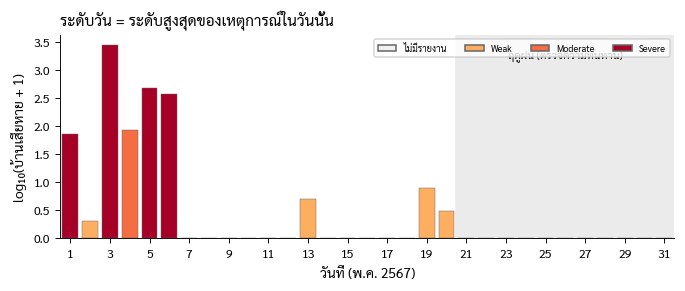

In [5]:
DAYS = pd.date_range("2024-05-01", "2024-05-31")
DAYT = DM.day_table(EVm, DAYS, RULES)
DAYT["main"] = DAYT["day"].dt.day.between(*MAIN)
print(DAYT[DAYT["main"]].groupby("day_class", observed=True)["day"].apply(lambda d: ", ".join(f"{x:%d}" for x in d)).to_string())
fig, ax = plt.subplots(figsize=(7.2, 2.4))
cc = {"None": "#f0f0f0", "Weak": COL["Weak"], "Moderate": COL["Moderate"], "Severe": COL["Severe"]}
ax.bar(DAYT["day"].dt.day, np.log10(DAYT["houses"].fillna(0) + 1), color=[cc[str(c)] for c in DAYT["day_class"]], ec="0.4", lw=0.3)
ax.axvspan(MAIN[1] + 0.5, 31.5, color="0.92", zorder=0); ax.text(26, 3.2, "ฤดูฝน (ตรวจความทนทาน)", ha="center", fontsize=7)
ax.set_xlim(0.5, 31.5); ax.set_xticks(range(1, 32, 2)); ax.set_ylabel("log₁₀(บ้านเสียหาย + 1)"); ax.set_xlabel("วันที่ (พ.ค. 2567)")
from matplotlib.patches import Patch
ax.legend([Patch(fc=v, ec="0.4") for v in cc.values()], ["ไม่มีรายงาน"] + CLS3, ncol=4, fontsize=6, loc="upper right")
ax.set_title("ระดับวัน = ระดับสูงสุดของเหตุการณ์ในวันนั้น", loc="left")
M.savefig(fig, "nb07_day_classes"); plt.show()

## 3. กลุ่มของเส้นทาง: C / B / A-ระดับ

| กลุ่ม | นิยาม | ใช้ตอบ |
|---|---|---|
| **A** (Weak / Moderate / Severe) | จับคู่กับอำเภอ-วันที่มีความเสียหาย (ระดับ = ระดับของเหตุการณ์) | พายุที่ทำความเสียหาย |
| **B** | วันเดียวกับวันที่มีรายงาน แต่ไม่จับคู่ | **A vs B** = บรรยากาศเดียวกัน ความต่างมาจากตัวพายุ |
| **C** | วันที่ไม่มีรายงาน | **A vs C** = คำถาม "วันมีรายงาน vs ไม่มีรายงาน" ในระดับพายุ |

**เส้นทางตัวแทน:** อำเภอ-วันหนึ่งอาจจับคู่ได้หลายเส้น (เซลล์เล็ก ๆ รอบพายุหลัก) การวิเคราะห์หลักใช้ **เส้นที่ซ้อนทับอำเภอมากที่สุด** หนึ่งเส้นต่ออำเภอ-วัน (ใช้ทุกเส้นเป็นการตรวจความทนทาน)

**ตัดออกจากการวิเคราะห์หลัก:** เส้นทางที่ footprint อยู่ในเขตลำคลื่นถูกบัง > 25% (P5) เพราะเรดาร์เห็นพายุเหล่านี้ไม่ครบ

In [6]:
RDAYS = DD.loc[~DD["excluded"] & (DD["coverage"] != "นอกรัศมี"), "date"]   # วันท้องถิ่นที่มีรายงานในรัศมี (ไม่นับแถวที่ตัดออก)
def build_groups(tag, main_only=True, rep_only=True, drop_blocked=True, col="event_class3", pairs=None, dd=None):
    L = DM.label_tracks(TR[tag], PAIRS[tag] if pairs is None else pairs, DD if dd is None else dd, RDAYS, col=col)
    L["day_local"] = pd.to_datetime(L["day_local"])
    if main_only:
        L = L[L["day_local"].dt.day.between(*MAIN)]
    if drop_blocked:
        L = L[~(L["frac_blocked"] > 0.25)]
    if rep_only:
        L = L[~L["is_A"] | L["is_rep"]]
    L = L[L["group5"] != "A-unknown"].copy()
    L["lh"] = (pd.to_datetime(L["start"]) + pd.Timedelta(hours=7)).dt.hour
    L["rbin"] = pd.cut(L["range_km"], [0, 100, 160, 250], labels=["<100", "100–160", ">160"])
    L["log_pop"] = np.log10(L["pop_fp"].clip(lower=1))
    return L
GR = {tag: build_groups(tag) for tag in TAGS}
pd.DataFrame({tag: g["group5"].value_counts().reindex(ORDER) for tag, g in GR.items()}).fillna(0).astype(int)

,15min,10min_linZ,05min_linZ
group5,,,
C,859,861,909
B,716,778,820
Weak,13,15,16
Moderate,2,2,2
Severe,11,9,11


In [7]:
VARS = {  # ตัวแปร: (ชื่อไทย, หมวด)
    "deq_max": ("ขนาด D_eq สูงสุด (km)", "ขนาด/การเคลื่อนที่"), "lifetime_min": ("อายุ (นาที)", "ขนาด/การเคลื่อนที่"),
    "speed_kmh": ("ความเร็ว (km/h)", "ขนาด/การเคลื่อนที่"), "growth_max_km2h": ("อัตราโตสูงสุด (km²/ชม.)", "ขนาด/การเคลื่อนที่"),
    "Zmax_obs": ("Z สูงสุด (dBZ)", "Reflectivity"), "A45_max_obs": ("พื้นที่ ≥45 dBZ (km²)", "Reflectivity"),
    "hail_col_km2": ("ลูกเห็บในคอลัมน์ (km²)", "Dual-pol"), "hail_low_frac": ("สัดส่วนลูกเห็บชั้นล่าง", "Dual-pol"),
    "KDP95": ("KDP p95 (°/km)", "Dual-pol"), "ZDR90": ("ZDR p90 (dB)", "Dual-pol"), "graupel_up_frac": ("graupel ชั้นบน", "Dual-pol"),
    "DIVmax": ("divergence สูงสุด (10⁻³ s⁻¹)", "Doppler"), "AZSmax": ("|az. shear| สูงสุด (10⁻³ s⁻¹)", "Doppler"),
    "V95": ("|V| p95 (m/s)", "Doppler"), "EDR95": ("EDR p95", "Doppler"),
}

## 4. ระดับวัน: วันที่ไม่มีรายงาน vs วัน Weak / Moderate / Severe

หน่วยวิเคราะห์ = วัน (n = 20 ในช่วงหลัก) จึงไม่มีปัญหาเส้นทางในวันเดียวกันไม่อิสระ แต่ตัวอย่างน้อย — เน้น **ขนาดผลและแนวโน้ม** (Jonckheere–Terpstra) ไม่ใช่ p-value อย่างเดียว

**Jonckheere–Terpstra:** สำหรับกลุ่มที่เรียงลำดับ $g_1 < g_2 < \dots$

$$J = \sum_{i<j} \#\{(x, y): x\in g_i,\ y \in g_j,\ y > x\} + \tfrac12\#\{y = x\}$$

$J$ ใหญ่ = ค่ามีแนวโน้มเพิ่มตามลำดับกลุ่ม (p จากการสลับป้าย)

In [8]:
st = D.table("volume_stats_p1.csv"); st = st[st["status"] == "ok"]
st["day"] = (st["slot_utc"] + pd.Timedelta(hours=7)).dt.normalize()            # วันท้องถิ่น ให้ตรงกับรายงาน
dv = st.groupby("day").agg(max_A35=("area_ge35_km2", "max"), max_A45=("area_ge45_km2", "max"),
                           sum_A45=("area_ge45_km2", "sum"), max_Zcol=("col_max_dbz", "max"))
Tall = TR["15min"].copy(); Tall["day"] = pd.to_datetime(Tall["day_local"])
dt_ = Tall.groupby("day").agg(n_tracks=("uid", "size"), hail_p90=("hail_col_km2", lambda x: x.quantile(0.9)),
                              KDP_p90=("KDP95", lambda x: x.quantile(0.9)), DIV_p90=("DIVmax", lambda x: x.quantile(0.9)))
DV = DAYT.set_index("day").join(dv).join(dt_)
DVm = DV[DV["main"]]
dorder = ["None"] + CLS3
rows = []
for v in ["max_A35", "max_A45", "sum_A45", "max_Zcol", "n_tracks", "hail_p90", "KDP_p90", "DIV_p90"]:
    z, p = DM.jonckheere(DVm[v], DVm["day_class"].astype(str), dorder, n_perm=4999)
    med = DVm.groupby("day_class", observed=True)[v].median()
    rows.append({"ตัวแปรรายวัน": v, **{f"มัธยฐาน {k}": med.get(k, np.nan) for k in dorder}, "JT z": z, "p (แนวโน้ม)": p})
DAYRES = pd.DataFrame(rows).set_index("ตัวแปรรายวัน")
DAYRES["q (FDR)"] = DM.fdr_bh(DAYRES["p (แนวโน้ม)"])
print("จำนวนวัน:", DVm["day_class"].value_counts().reindex(dorder).to_dict())
DAYRES.round(3)

จำนวนวัน: {'None': 11, 'Weak': 4, 'Moderate': 1, 'Severe': 4}


,มัธยฐาน None,มัธยฐาน Weak,มัธยฐาน Moderate,มัธยฐาน Severe,JT z,p (แนวโน้ม),q (FDR)
ตัวแปรรายวัน,,,,,,,
max_A35,1006.000,2527.500,1525.000,1421.000,0.101,0.481,0.521
max_A45,130.000,223.000,153.000,187.500,1.053,0.166,0.221
sum_A45,1923.000,4101.000,3742.000,3917.000,1.328,0.098,0.197
max_Zcol,56.500,59.250,60.000,58.000,0.998,0.164,0.221
n_tracks,69.000,119.500,75.000,80.500,-0.017,0.521,0.521
hail_p90,64.600,78.150,145.600,87.800,1.887,0.033,0.132
KDP_p90,2.008,2.542,2.924,2.490,1.602,0.060,0.159
DIV_p90,1.995,2.526,5.322,3.954,3.196,0.000,0.002


บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb07_day_level.png / .pdf


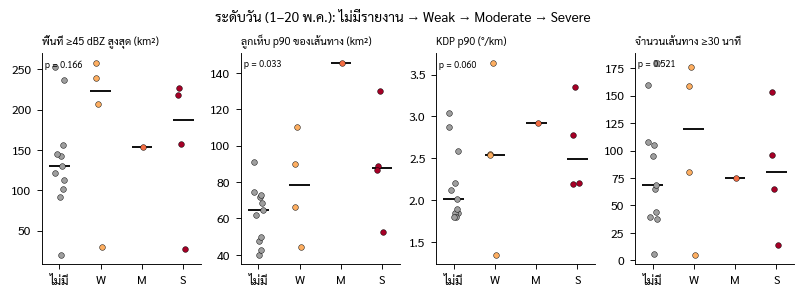

In [9]:
fig, axs = plt.subplots(1, 4, figsize=(7.2, 2.6), layout="constrained")
for ax, v, lab in zip(axs, ["max_A45", "hail_p90", "KDP_p90", "n_tracks"],
                      ["พื้นที่ ≥45 dBZ สูงสุด (km²)", "ลูกเห็บ p90 ของเส้นทาง (km²)", "KDP p90 (°/km)", "จำนวนเส้นทาง ≥30 นาที"]):
    for i, k in enumerate(dorder):
        y = DVm.loc[DVm["day_class"] == k, v]
        ax.scatter(np.full(len(y), i) + np.random.default_rng(0).uniform(-0.12, 0.12, len(y)), y, s=14,
                   color=["#9e9e9e", COL["Weak"], COL["Moderate"], COL["Severe"]][i], ec="k", lw=0.3, zorder=3)
        if len(y):
            ax.hlines(y.median(), i - 0.25, i + 0.25, color="k", lw=1.2)
    ax.set_xticks(range(4), ["ไม่มี", "W", "M", "S"]); ax.set_title(lab, fontsize=7, loc="left")
    ax.text(0.02, 0.97, f"p = {DAYRES.loc[v, 'p (แนวโน้ม)']:.3f}", transform=ax.transAxes, va="top", fontsize=6)
fig.suptitle("ระดับวัน (1–20 พ.ค.): ไม่มีรายงาน → Weak → Moderate → Severe", fontsize=9)
M.savefig(fig, "nb07_day_level"); plt.show()

## 5. ระดับเส้นทาง (แบบรวม): A vs C และ A vs B ทุก Δt

**ขนาดผล:** Cliff's $\delta = P(X_A > X_{ref}) - P(X_A < X_{ref})$ (−1 ถึง 1) พร้อม CI 95% จาก **bootstrap แบบสุ่มวัน** (เส้นทางในวันเดียวกันไม่อิสระ)

**p-value จากการสลับป้ายภายในชั้น:**
- A vs B: สลับภายใน **วันเดียวกัน** (ควบคุมบรรยากาศ)
- A vs C: สลับภายในชั้น **ช่วงระยะเรดาร์ × ช่วงเวลา 3 ชม.** (ควบคุมเรขาคณิตการสแกนและวัฏจักรรายวัน)

แล้วปรับการทดสอบหลายตัวแปรด้วย **Benjamini–Hochberg FDR** (q-value)

In [10]:
def pooled(L, ref, n_perm=1999, n_boot=300):
    rows = []
    for v in VARS:
        if v not in L:
            continue
        sub = L[L["group3"].isin(["A", ref])]
        case = (sub["group3"] == "A").values
        strata = sub["day_local"].astype(str) if ref == "B" else sub["rbin"].astype(str) + "_" + (sub["lh"] // 3).astype(str)
        d, p, n1, n2 = DM.strat_perm_delta(sub[v], case, strata, n_perm=n_perm)
        _, lo, hi = DM.cluster_bootstrap_delta(sub.loc[case, v], sub.loc[~case, v], sub.loc[case, "day_local"],
                                               sub.loc[~case, "day_local"], n_boot=n_boot)
        rows.append({"var": v, "ref": ref, "delta": d, "lo": lo, "hi": hi, "p": p, "nA": n1, "nRef": n2,
                     "med_A": sub.loc[case, v].median(), "med_ref": sub.loc[~case, v].median()})
    out = pd.DataFrame(rows); out["q"] = DM.fdr_bh(out["p"]); return out
POOL = pd.concat([pooled(GR[t], ref).assign(tag=t) for t in TAGS for ref in ("C", "B")], ignore_index=True)
P15 = POOL[POOL["tag"] == "15min"].pivot(index="var", columns="ref", values=["delta", "lo", "hi", "q", "med_A", "med_ref"])
P15.reindex(list(VARS)).round(3)

delta            lo            hi             q           med_A           med_ref         
ref                  B      C      B      C      B      C      B      C        B        C        B        C
var                                                                                                        
deq_max          0.345  0.466  0.132  0.225  0.628  0.677  0.020  0.001   13.889   13.889   11.227   10.280
lifetime_min     0.248  0.263  0.101  0.099  0.570  0.578  0.039  0.018   45.000   45.000   45.000   45.000
speed_kmh        0.267  0.481 -0.038  0.201  0.682  0.793  0.294  0.001   12.552   12.552    9.614    7.285
growth_max_km2h  0.287  0.388  0.093  0.154  0.581  0.642  0.030  0.002  288.000  288.000  172.000  148.000
Zmax_obs         0.139  0.258 -0.071  0.058  0.382  0.510  0.294  0.105   49.950   49.950   49.000   48.500
A45_max_obs      0.333  0.503  0.142  0.337  0.579  0.744  0.021  0.001   14.000   14.000    8.000    6.000
hail_col_km2     0.485  0.651  0.311  0.524  0.767  0.841  0.008  0.001   64.500   64.500   29.500   19.000
hail_low_frac    0.179  0.244  0.020  0.097  0.578  0.565  0.372  0.171    0.392    0.392    0.328    0.292
KDP95            0.321  0.420  0.020  0.080  0.683  0.751  0.020  0.001    2.055    2.055    1.390    1.210
ZDR90            0.113  0.160 -0.080 -0.017  0.408  0.420  0.508  0.636    4.371    4.371    4.230    4.209
graupel_up_frac  0.193  0.211  0.027  0.046  0.328  0.329  0.294  0.038    0.278    0.278    0.235    0.216
DIVmax           0.295  0.483  0.111  0.302  0.571  0.679  0.042  0.001    1.635    1.635    1.190    0.980
AZSmax           0.285  0.387 -0.079 -0.014  0.638  0.694  0.042  0.001    1.200    1.200    0.730    0.570
V95              0.204  0.523 -0.036  0.297  0.584  0.756  0.294  0.001    9.310    9.310    7.700    5.875
EDR95            0.114  0.047 -0.199 -0.234  0.305  0.293  0.372  0.636    0.191    0.191    0.185    0.189

บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb07_effect_heatmap.png / .pdf


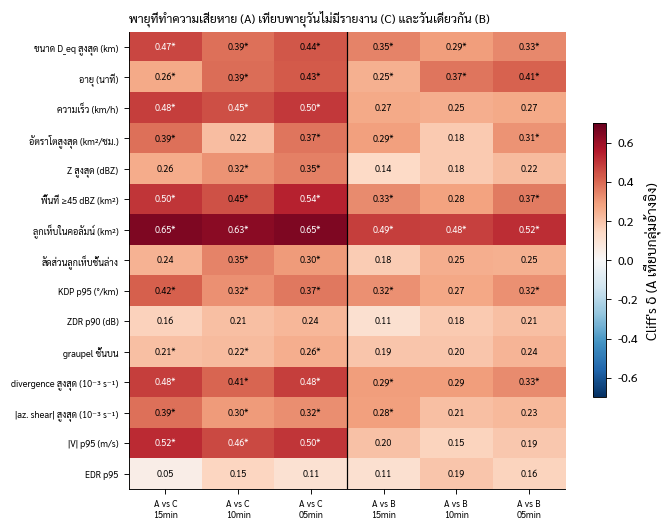

In [11]:
# heatmap ขนาดผล: ตัวแปร × (เทียบกับ C, B) × Δt   (ดอกจัน = q < 0.05)
cols = [(r, t) for r in ("C", "B") for t in TAGS]
Hm = np.array([[POOL.query("var == @v and ref == @r and tag == @t")["delta"].squeeze() for r, t in cols] for v in VARS])
Q = np.array([[POOL.query("var == @v and ref == @r and tag == @t")["q"].squeeze() for r, t in cols] for v in VARS])
fig, ax = plt.subplots(figsize=(6.4, 5.4))
im = ax.imshow(Hm, cmap="RdBu_r", vmin=-0.7, vmax=0.7, aspect="auto")
for i in range(Hm.shape[0]):
    for j in range(Hm.shape[1]):
        ax.text(j, i, f"{Hm[i, j]:.2f}" + ("*" if Q[i, j] < 0.05 else ""), ha="center", va="center", fontsize=6,
                color="w" if abs(Hm[i, j]) > 0.45 else "k")
ax.set_xticks(range(len(cols)), [f"A vs {r}\n{t.split('_')[0]}" for r, t in cols], fontsize=6)
ax.set_yticks(range(len(VARS)), [VARS[v][0] for v in VARS], fontsize=6)
ax.axvline(2.5, color="k", lw=0.8)
fig.colorbar(im, ax=ax, shrink=0.6, label="Cliff's δ (A เทียบกลุ่มอ้างอิง)")
ax.set_title("พายุที่ทำความเสียหาย (A) เทียบพายุวันไม่มีรายงาน (C) และวันเดียวกัน (B)", loc="left", fontsize=8)
M.savefig(fig, "nb07_effect_heatmap"); plt.show()

## 6. แยกระดับ (dose–response): C ≤ B < Weak < Moderate < Severe

ถ้าตัวแปรเรดาร์ **เพิ่มขึ้นเป็นขั้นตามระดับความเสียหาย** คือหลักฐานที่หนักแน่นที่สุดว่าตัวแปรนั้นสะท้อนความรุนแรงของภัยจริง (ไม่ใช่แค่ "มี/ไม่มีรายงาน") — ใช้ Jonckheere–Terpstra โดยสลับป้ายภายในชั้นช่วงระยะเรดาร์ และดูแนวโน้ม **เฉพาะในกลุ่ม A** (Weak < Moderate < Severe) แยกด้วย

In [12]:
def dose(L, n_perm=999):
    rows = []
    for v in VARS:
        if v not in L:
            continue
        z, p = DM.jonckheere(L[v], L["group5"], ORDER, n_perm=n_perm, strata=L["rbin"].astype(str))
        a = L[L["is_A"]]
        za, pa = DM.jonckheere(a[v], a["group5"], CLS3, n_perm=n_perm)
        med = L.groupby("group5")[v].median()
        rows.append({"var": v, **{k: med.get(k, np.nan) for k in ORDER}, "JT_z_all": z, "p_all": p, "JT_z_Aonly": za, "p_Aonly": pa})
    out = pd.DataFrame(rows); out["q_all"] = DM.fdr_bh(out["p_all"]); out["q_Aonly"] = DM.fdr_bh(out["p_Aonly"]); return out
DOSE = {t: dose(GR[t]).assign(tag=t) for t in TAGS}
DOSE["15min"].set_index("var").round(3)

,C,B,Weak,Moderate,Severe,JT_z_all,p_all,JT_z_Aonly,p_Aonly,q_all,q_Aonly,tag
var,,,,,,,,,,,,
deq_max,10.280,11.227,13.493,15.532,15.430,5.491,0.001,2.662,0.003,0.002,0.022,15min
lifetime_min,45.000,45.000,45.000,75.000,60.000,0.992,0.166,1.293,0.094,0.178,0.157,15min
speed_kmh,7.285,9.614,9.263,18.677,20.113,8.923,0.001,2.776,0.002,0.002,0.022,15min
growth_max_km2h,148.000,172.000,208.000,316.000,380.000,4.410,0.001,2.348,0.009,0.002,0.034,15min
Zmax_obs,48.500,49.000,50.500,48.250,49.000,4.012,0.001,-2.261,0.990,0.002,0.990,15min
A45_max_obs,6.000,8.000,16.000,9.500,13.000,6.513,0.001,-1.078,0.863,0.002,0.990,15min
hail_col_km2,19.000,29.500,38.000,109.500,97.000,9.340,0.001,2.175,0.012,0.002,0.036,15min
hail_low_frac,0.292,0.328,0.321,0.666,0.372,3.042,0.002,0.838,0.216,0.003,0.295,15min
KDP95,1.210,1.390,1.196,2.754,2.174,4.879,0.001,2.079,0.016,0.002,0.040,15min


บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb07_dose_response.png / .pdf


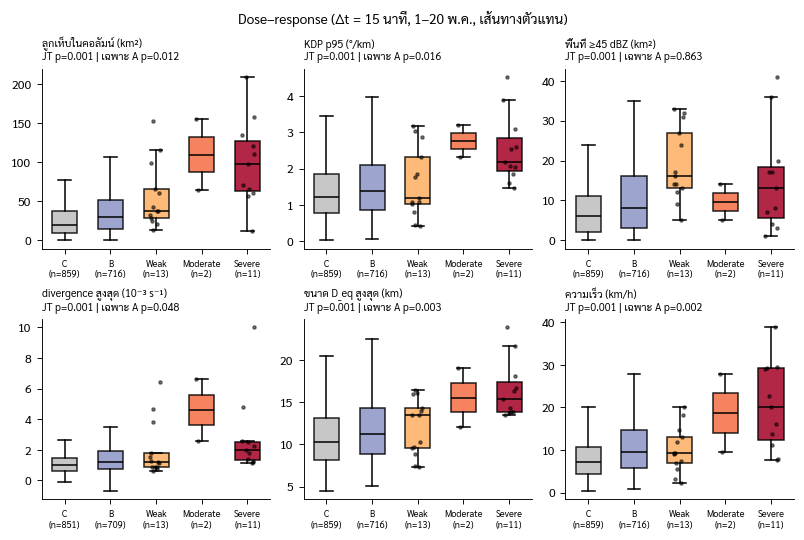

In [13]:
key6 = ["hail_col_km2", "KDP95", "A45_max_obs", "DIVmax", "deq_max", "speed_kmh"]
L = GR["15min"]
fig, axs = plt.subplots(2, 3, figsize=(7.2, 4.8), layout="constrained")
for ax, v in zip(axs.ravel(), key6):
    data = [L.loc[L["group5"] == k, v].dropna() for k in ORDER]
    bp = ax.boxplot(data, widths=0.55, showfliers=False, patch_artist=True, medianprops=dict(color="k"))
    for patch, k in zip(bp["boxes"], ORDER):
        patch.set_facecolor(COL[k]); patch.set_alpha(0.85)
    for i, d in enumerate(data):
        if ORDER[i] not in ("C", "B"):
            ax.scatter(np.full(len(d), i + 1) + np.random.default_rng(i).uniform(-0.15, 0.15, len(d)), d, s=4, color="k", alpha=0.5, zorder=3)
    ax.set_xticks(range(1, 6), [f"{k}\n(n={len(d)})" for k, d in zip(ORDER, data)], fontsize=6)
    r = DOSE["15min"].set_index("var").loc[v]
    ax.set_title(f"{VARS[v][0]}\nJT p={r['p_all']:.3f} | เฉพาะ A p={r['p_Aonly']:.3f}", fontsize=7, loc="left")
fig.suptitle("Dose–response (Δt = 15 นาที, 1–20 พ.ค., เส้นทางตัวแทน)", fontsize=9)
M.savefig(fig, "nb07_dose_response"); plt.show()

## 7. Matched case–control: ตัดผลของระยะ เวลา และขนาดออกพร้อมกัน

สำหรับเส้นทาง A แต่ละเส้น เลือกเส้นทาง C ที่ **ช่วงระยะเดียวกัน, เวลาท้องถิ่นต่างไม่เกิน 2 ชม., ขนาด D_eq ต่างไม่เกิน 30%** ได้สูงสุด 5 เส้น แล้วใช้ **conditional logistic regression** (เปรียบเทียบภายในชุดที่จับคู่) — odds ratio ต่อ 1 SD บอกว่าตัวแปรนั้นเพิ่มโอกาสเป็นพายุที่ทำความเสียหายเท่าไร **ที่ระยะ เวลา และขนาดเท่ากัน**

In [14]:
from statsmodels.discrete.conditional_models import ConditionalLogit
def matched_sets(L, k=5, seed=0):
    rng = np.random.default_rng(seed); Aa = L[L["is_A"]]; Cc = L[L["group5"] == "C"]; rows = []
    for sid, (_, a) in enumerate(Aa.iterrows()):
        pool = Cc[(Cc["rbin"] == a["rbin"]) & ((Cc["lh"] - a["lh"]).abs() <= 2) &
                  ((Cc["deq_max"] / a["deq_max"] - 1).abs() <= 0.3)]
        if len(pool) == 0:
            continue
        ctl = pool.iloc[rng.choice(len(pool), min(k, len(pool)), replace=False)]
        rows += [a.to_frame().T.assign(set_id=sid, case=1), ctl.assign(set_id=sid, case=0)]
    return pd.concat(rows, ignore_index=True)
MS_ = matched_sets(GR["15min"])
print(f"ชุดที่จับคู่ได้ {MS_['set_id'].nunique()} จาก {int(GR['15min']['is_A'].sum())} เส้นทาง A | ควบคุม {int((MS_['case'] == 0).sum())} เส้น")
rows = []
for v in VARS:
    d = MS_[["set_id", "case", v]].dropna()
    d = d[d.groupby("set_id")["case"].transform("nunique") == 2]
    if d["set_id"].nunique() < 8 or d[v].astype(float).std() == 0:
        continue
    x = ((d[v].astype(float) - d[v].astype(float).mean()) / d[v].astype(float).std()).to_frame()
    try:
        r = ConditionalLogit(d["case"].astype(int), x, groups=d["set_id"]).fit(disp=0)
        b, se = r.params.iloc[0], r.bse.iloc[0]
        rows.append({"ตัวแปร": VARS[v][0], "OR ต่อ 1 SD": np.exp(b), "CI ล่าง": np.exp(b - 1.96 * se), "CI บน": np.exp(b + 1.96 * se),
                     "p": r.pvalues.iloc[0], "n ชุด": d["set_id"].nunique()})
    except Exception as e:
        print(v, type(e).__name__)
CCL = pd.DataFrame(rows); CCL["q"] = DM.fdr_bh(CCL["p"])
CCL.sort_values("OR ต่อ 1 SD", ascending=False).round(3)

ชุดที่จับคู่ได้ 26 จาก 26 เส้นทาง A | ควบคุม 130 เส้น


,ตัวแปร,OR ต่อ 1 SD,CI ล่าง,CI บน,p,n ชุด,q
6,ลูกเห็บในคอลัมน์ (km²),4.701,2.139,10.334,0.000,26,0.002
0,ขนาด D_eq สูงสุด (km),3.600,1.637,7.917,0.001,26,0.007
12,|az. shear| สูงสุด (10⁻³ s⁻¹),2.942,1.136,7.619,0.026,26,0.056
2,ความเร็ว (km/h),2.507,1.536,4.092,0.000,26,0.002
8,KDP p95 (°/km),2.077,1.136,3.799,0.018,26,0.044
13,|V| p95 (m/s),1.944,1.241,3.044,0.004,26,0.014
11,divergence สูงสุด (10⁻³ s⁻¹),1.655,1.106,2.476,0.014,26,0.043
5,พื้นที่ ≥45 dBZ (km²),1.634,1.041,2.567,0.033,26,0.062
10,graupel ชั้นบน,1.596,0.975,2.611,0.063,26,0.105
7,สัดส่วนลูกเห็บชั้นล่าง,1.591,0.940,2.695,0.084,26,0.126


## 8. Hazard vs exposure: ทำไมบางพายุรุนแรงจึงไม่มีรายงาน

**ดัชนีภัย (hazard index):** ค่าเฉลี่ยของ z-score ของ ลูกเห็บในคอลัมน์, KDP95, พื้นที่ ≥45 dBZ และ divergence สูงสุด (ตัวแปรที่สะท้อนความรุนแรงทั้งลูกเห็บและลม) · **การสัมผัสภัย:** $\log_{10}$ ประชากรใต้ footprint (GHSL)

$$\text{logit}\,P(\text{A}) = \beta_0 + \beta_H\,H + \beta_E \log_{10}\text{pop} + \beta_r\,\text{range}$$

CI ของสัมประสิทธิ์จาก bootstrap แบบสุ่มวัน

In [15]:
from sklearn.linear_model import LogisticRegression
def hazard_index(L, ref=None):
    ref = L if ref is None else ref
    cols = ["hail_col_km2", "KDP95", "A45_max_obs", "DIVmax"]
    z = [(L[c] - ref[c].mean()) / ref[c].std() for c in cols]
    return pd.concat(z, axis=1).mean(axis=1, skipna=True)
L = GR["15min"].copy()
L["H"] = hazard_index(L)
L["rng100"] = L["range_km"] / 100
dfm = L.dropna(subset=["H", "log_pop", "rng100"])
Xc, y = ["H", "log_pop", "rng100"], dfm["is_A"].astype(int)
fit = LogisticRegression(C=1e6, max_iter=1000).fit(dfm[Xc], y)
days_u = dfm["day_local"].unique(); rng = np.random.default_rng(0); B = []
for _ in range(300):
    pick = rng.choice(days_u, len(days_u))
    bs = pd.concat([dfm[dfm["day_local"] == d] for d in pick])
    if bs["is_A"].nunique() == 2:
        B.append(LogisticRegression(C=1e6, max_iter=1000).fit(bs[Xc], bs["is_A"].astype(int)).coef_[0])
B = np.array(B)
HE = pd.DataFrame({"β": fit.coef_[0], "CI ล่าง": np.percentile(B, 2.5, 0), "CI บน": np.percentile(B, 97.5, 0),
                   "OR": np.exp(fit.coef_[0])}, index=["ดัชนีภัย (ต่อ 1 หน่วย z)", "log10 ประชากรใต้ footprint", "ระยะ (ต่อ 100 km)"])
HE.round(3)

,β,CI ล่าง,CI บน,OR
ดัชนีภัย (ต่อ 1 หน่วย z),0.539,0.256,1.167,1.714
log10 ประชากรใต้ footprint,1.369,0.826,2.058,3.932
ระยะ (ต่อ 100 km),0.076,-0.556,1.005,1.079


บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb07_hazard_exposure.png / .pdf


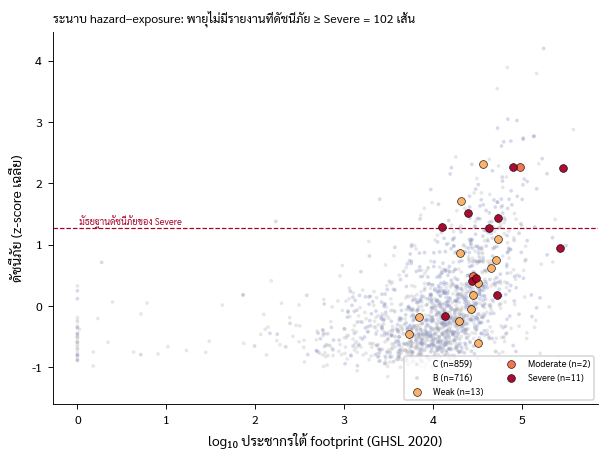

ผู้สมัคร "พายุรุนแรงที่ไม่ถูกรายงาน" 10 อันดับแรก (ให้นิสิตค้นข่าวยืนยัน):


,uid,start,group5,range_km,start_lat,start_lon,H,pop_fp,hail_col_km2,KDP95
998,E017-0174,2024-05-13 07:45:00,B,30.96,16.35,102.47,4.20,176440.0,273,6.26
1334,E021-0458,2024-05-17 05:45:00,C,183.64,15.14,101.66,3.89,68765.0,245,3.19
2311,E038-0150,2024-05-31 18:15:00,C,60.58,15.92,102.33,3.79,147060.0,306,5.57
796,E013-0242,2024-05-10 11:30:00,C,36.79,16.16,102.97,3.54,53020.0,188,5.80
1061,E017-0283,2024-05-13 12:30:00,B,140.69,17.17,103.84,3.05,69702.0,214,3.47
1054,E017-0271,2024-05-13 11:45:00,B,164.15,17.91,103.38,3.03,88125.0,185,4.40
1006,E017-0198,2024-05-13 08:30:00,B,36.87,16.24,103.03,2.90,53299.0,178,4.93
805,E013-0261,2024-05-10 12:30:00,C,12.02,16.35,102.83,2.88,380840.0,116,7.93
940,E017-0057,2024-05-13 04:45:00,B,179.51,16.15,104.47,2.77,138050.0,280,4.17
1024,E017-0224,2024-05-13 10:00:00,B,153.49,17.66,103.92,2.77,135600.0,155,3.58


In [16]:
sev_thr = L.loc[L["group5"] == "Severe", "H"].median()
cand = L[(~L["is_A"]) & (L["H"] >= sev_thr)].sort_values("H", ascending=False)
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for k in ORDER:
    d = L[L["group5"] == k]
    ax.scatter(d["log_pop"], d["H"], s=6 if k in ("C", "B") else 26, color=COL[k], alpha=0.35 if k in ("C", "B") else 0.95,
               ec="none" if k in ("C", "B") else "k", lw=0.4, label=f"{k} (n={len(d)})", zorder=2 if k in ("C", "B") else 4)
ax.axhline(sev_thr, color=COL["Severe"], ls="--", lw=0.8)
ax.text(L["log_pop"].min(), sev_thr, " มัธยฐานดัชนีภัยของ Severe", va="bottom", fontsize=6, color=COL["Severe"])
ax.set_xlabel("log₁₀ ประชากรใต้ footprint (GHSL 2020)"); ax.set_ylabel("ดัชนีภัย (z-score เฉลี่ย)")
ax.legend(fontsize=6, ncol=2, loc="lower right")
ax.set_title(f"ระนาบ hazard–exposure: พายุไม่มีรายงานที่ดัชนีภัย ≥ Severe = {len(cand)} เส้น", loc="left", fontsize=8)
M.savefig(fig, "nb07_hazard_exposure"); plt.show()
print("ผู้สมัคร \"พายุรุนแรงที่ไม่ถูกรายงาน\" 10 อันดับแรก (ให้นิสิตค้นข่าวยืนยัน):")
cand[["uid", "start", "group5", "range_km", "start_lat", "start_lon", "H", "pop_fp", "hail_col_km2", "KDP95"]].head(10).round(2)

## 9. ความสามารถจำแนก: reflectivity เท่านั้น vs + dual-pol vs + Doppler vs + exposure

Logistic regression (standardize + เติมค่าขาดด้วยมัธยฐาน) ประเมินด้วย **cross-validation แบบเว้นทีละวัน** (LeaveOneGroupOut) — ถ้าสุ่มแบ่งเส้นทาง เส้นทางในวันเดียวกันจะอยู่ทั้งชุดฝึกและชุดทดสอบ ทำให้ AUC สูงเกินจริง (data leakage) รายงาน ROC-AUC และ PR-AUC (กลุ่มไม่สมดุล A ≪ B + C)

In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score
SETS = {"Z": ["Zmax_obs", "A45_max_obs", "deq_max", "lifetime_min", "range_km"]}
SETS["Z+dualpol"] = SETS["Z"] + ["hail_col_km2", "hail_low_frac", "KDP95", "ZDR90", "graupel_up_frac"]
SETS["Z+dualpol+Doppler"] = SETS["Z+dualpol"] + ["DIVmax", "AZSmax", "V95", "EDR95"]
SETS["+exposure"] = SETS["Z+dualpol+Doppler"] + ["log_pop"]
rows, PRED = [], {}
for tag in TAGS:
    Lt = GR[tag]
    for name, cols in SETS.items():
        mdl = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000, C=0.5))
        p = cross_val_predict(mdl, Lt[cols], Lt["is_A"].astype(int), groups=Lt["day_local"], cv=LeaveOneGroupOut(),
                              method="predict_proba")[:, 1]
        yv = Lt["is_A"].astype(int).values
        # CI จาก bootstrap รายวันของค่าทำนาย
        dd_ = Lt["day_local"].values; du = np.unique(dd_); rng = np.random.default_rng(1); bs = []
        for _ in range(300):
            ix = np.concatenate([np.flatnonzero(dd_ == d) for d in rng.choice(du, len(du))])
            if yv[ix].min() != yv[ix].max():
                bs.append(roc_auc_score(yv[ix], p[ix]))
        rows.append({"tag": tag, "set": name, "AUC": roc_auc_score(yv, p), "AUC_lo": np.percentile(bs, 2.5),
                     "AUC_hi": np.percentile(bs, 97.5), "PR_AUC": average_precision_score(yv, p), "base_rate": yv.mean()})
        PRED[(tag, name)] = (yv, p)
AUC = pd.DataFrame(rows)
AUC.pivot(index="set", columns="tag", values="AUC").reindex(list(SETS)).round(3)

tag,05min_linZ,10min_linZ,15min
set,,,
Z,0.600,0.535,0.537
Z+dualpol,0.635,0.543,0.610
Z+dualpol+Doppler,0.638,0.553,0.643
+exposure,0.689,0.651,0.728


บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb07_auc.png / .pdf


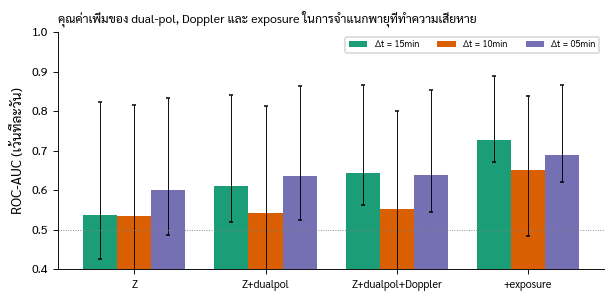

In [18]:
fig, ax = plt.subplots(figsize=(6.4, 2.8))
w = 0.26
for i, tag in enumerate(TAGS):
    a = AUC[AUC["tag"] == tag].set_index("set").reindex(list(SETS))
    xs = np.arange(len(SETS)) + (i - 1) * w
    ax.bar(xs, a["AUC"], width=w, color=["#1b9e77", "#d95f02", "#7570b3"][i], label=f"Δt = {tag.split('_')[0]}")
    ax.errorbar(xs, a["AUC"], yerr=[a["AUC"] - a["AUC_lo"], a["AUC_hi"] - a["AUC"]], fmt="none", ecolor="k", lw=0.6, capsize=1.5)
ax.axhline(0.5, color="0.5", lw=0.6, ls=":")
ax.set_xticks(range(len(SETS)), list(SETS), fontsize=7); ax.set_ylim(0.4, 1); ax.set_ylabel("ROC-AUC (เว้นทีละวัน)")
ax.legend(fontsize=6, ncol=3); ax.set_title("คุณค่าเพิ่มของ dual-pol, Doppler และ exposure ในการจำแนกพายุที่ทำความเสียหาย", loc="left", fontsize=8)
M.savefig(fig, "nb07_auc"); plt.show()

## 10. ลูกเห็บ vs ลมอย่างเดียว: HID ตรวจลูกเห็บที่มีรายงานได้หรือไม่

รายงานทุกแถวเป็นลม มี 12 แถวที่รายงานลูกเห็บด้วย เปรียบเทียบเส้นทาง A ที่จับคู่กับอำเภอที่ **รายงานลูกเห็บ** กับ **ลมอย่างเดียว** และคำนวณ POD ของ HID (สัดส่วนอำเภอที่รายงานลูกเห็บซึ่งเส้นทางที่จับคู่มีลูกเห็บในคอลัมน์ > 0 km²) — n น้อย จึงเป็นการตรวจสอบเบื้องต้น

In [19]:
pr = PAIRS["15min"].merge(DD[["dd_id", "hail"]].rename(columns={"dd_id": "report_id"}), on="report_id")
pr = pr.merge(TR["15min"][["uid", "hail_col_km2", "hail_low_frac", "ZDR90", "KDP95", "Zmax_obs"]], on="uid")
per_dd = pr.groupby("report_id").agg(hail_rep=("hail", "first"), hail_col_km2=("hail_col_km2", "max"),
                                     hail_low_frac=("hail_low_frac", "max"), ZDR90=("ZDR90", "median"),
                                     KDP95=("KDP95", "max"), Zmax_obs=("Zmax_obs", "max"))
rows = []
for v in ["hail_col_km2", "hail_low_frac", "Zmax_obs", "KDP95", "ZDR90"]:
    a, b = per_dd.loc[per_dd["hail_rep"], v].dropna(), per_dd.loc[~per_dd["hail_rep"], v].dropna()
    rows.append({"ตัวแปร": v, "มัธยฐาน รายงานลูกเห็บ": a.median(), "มัธยฐาน ลมอย่างเดียว": b.median(), "n": f"{len(a)}/{len(b)}",
                 "Cliff δ": tt.cliffs_delta(a, b), "p (MWU)": stats.mannwhitneyu(a, b).pvalue if min(len(a), len(b)) >= 3 else np.nan})
hr = per_dd[per_dd["hail_rep"]]
print(f"POD ของ HID (ลูกเห็บในคอลัมน์ > 0) สำหรับอำเภอที่รายงานลูกเห็บ: {(hr['hail_col_km2'] > 0).mean():.0%} ({int((hr['hail_col_km2'] > 0).sum())}/{len(hr)})")
pd.DataFrame(rows).round(3)

POD ของ HID (ลูกเห็บในคอลัมน์ > 0) สำหรับอำเภอที่รายงานลูกเห็บ: 100% (11/11)


,ตัวแปร,มัธยฐาน รายงานลูกเห็บ,มัธยฐาน ลมอย่างเดียว,n,Cliff δ,p (MWU)
0,hail_col_km2,107.000,69.500,11/36,0.253,0.213
1,hail_low_frac,0.558,0.524,11/36,0.124,0.546
2,Zmax_obs,51.000,50.500,11/36,0.311,0.124
3,KDP95,2.603,2.380,11/36,0.078,0.706
4,ZDR90,4.614,4.268,11/36,0.462,0.022


## 11. ความทนทานของข้อสรุป

ทำซ้ำการทดสอบแนวโน้มของตัวแปรหลัก (ลูกเห็บในคอลัมน์, KDP95, ความเร็วพายุ) ภายใต้ทางเลือกต่าง ๆ ทั้งแบบทุกกลุ่ม (C ≤ B < A-ระดับ) และ **เฉพาะกลุ่ม A** (ระดับความเสียหายเรียงตามตัวแปรหรือไม่) — ข้อสรุปที่ดีควร **ไม่พลิก** เมื่อเปลี่ยนทางเลือกที่สมเหตุสมผล

In [20]:
def jt_for(L, order, v):
    """คืน (z, p) ของแนวโน้มทุกกลุ่ม และ (z, p) เฉพาะกลุ่ม A — แบบทุกกลุ่มถูกครอบงำด้วยคู่ C/B vs A (เส้นทางจำนวนมาก)
    จึงต้องดูแบบ "เฉพาะ A" เพื่อรู้ว่าการแบ่งระดับความเสียหายยังเรียงตามตัวแปรเรดาร์หรือไม่"""
    za, pa = DM.jonckheere(L[v], L["group5"], order, n_perm=999, strata=L["rbin"].astype(str))
    a = L[L["is_A"]]
    zb, pb = DM.jonckheere(a[v], a["group5"], [k for k in order if k not in ("C", "B")], n_perm=999)
    return za, pa, zb, pb
ORDER4 = ["C", "B"] + RULES["classes"]["robust4"]["labels"]
DDw = DD.copy(); DDw["event_class3"] = DDw["event_class3"].astype(object).where(DDw["event_class3"].notna(), "Weak")
DDw["event_class3"] = pd.Categorical(DDw["event_class3"], CLS3, ordered=True)
REP10 = REP.copy()
PAIRS10 = A.match_tracks_reports(FPs["15min"], TR["15min"], REP10, buffer_km=10)
scen = {
    "หลัก (3 ระดับ, ตัวแทน, 1–20 พ.ค., ตัดเขตถูกบัง)": (GR["15min"], ORDER),
    "4 ระดับ": (build_groups("15min", col="event_class4"), ORDER4),
    "ทั้งเดือน": (build_groups("15min", main_only=False), ORDER),
    "ไม่ทราบจำนวนบ้าน → Weak": (build_groups("15min", dd=DDw), ORDER),
    "ทุกเส้นที่จับคู่ (ไม่ใช่เฉพาะตัวแทน)": (build_groups("15min", rep_only=False), ORDER),
    "รวมเขตถูกบัง": (build_groups("15min", drop_blocked=False), ORDER),
    "บัฟเฟอร์จับคู่ 10 km": (build_groups("15min", pairs=PAIRS10), ORDER),
    "Δt = 10 นาที": (GR["10min_linZ"], ORDER), "Δt = 5 นาที": (GR["05min_linZ"], ORDER),
}
rows = []
for name, (Ls, order) in scen.items():
    r = {"สถานการณ์": name, "n A": int(Ls["is_A"].sum())}
    for v in ["hail_col_km2", "KDP95", "speed_kmh"]:
        za, pa, zb, pb = jt_for(Ls, order, v)
        r[f"{v} p(ทุกกลุ่ม)"] = pa; r[f"{v} z(เฉพาะ A)"] = zb; r[f"{v} p(เฉพาะ A)"] = pb
    rows.append(r)
ROB = pd.DataFrame(rows).set_index("สถานการณ์")
ROB.round(3)

,n A,hail_col_km2 p(ทุกกลุ่ม),hail_col_km2 z(เฉพาะ A),hail_col_km2 p(เฉพาะ A),KDP95 p(ทุกกลุ่ม),KDP95 z(เฉพาะ A),KDP95 p(เฉพาะ A),speed_kmh p(ทุกกลุ่ม),speed_kmh z(เฉพาะ A),speed_kmh p(เฉพาะ A)
สถานการณ์,,,,,,,,,,
"หลัก (3 ระดับ, ตัวแทน, 1–20 พ.ค., ตัดเขตถูกบัง)",26,0.001,2.175,0.012,0.001,2.079,0.016,0.001,2.776,0.002
4 ระดับ,26,0.001,1.983,0.021,0.001,1.954,0.025,0.001,2.090,0.015
ทั้งเดือน,27,0.001,2.248,0.016,0.001,2.212,0.018,0.002,2.893,0.001
ไม่ทราบจำนวนบ้าน → Weak,27,0.001,1.844,0.045,0.001,1.798,0.042,0.001,2.598,0.009
ทุกเส้นที่จับคู่ (ไม่ใช่เฉพาะตัวแทน),50,0.001,1.776,0.035,0.001,2.597,0.004,0.001,2.852,0.002
รวมเขตถูกบัง,33,0.001,1.258,0.116,0.001,0.892,0.186,0.001,3.114,0.001
บัฟเฟอร์จับคู่ 10 km,28,0.001,2.474,0.006,0.001,2.026,0.025,0.001,2.120,0.023
Δt = 10 นาที,26,0.001,2.264,0.016,0.004,2.054,0.019,0.001,2.250,0.013
Δt = 5 นาที,29,0.001,2.181,0.015,0.004,2.060,0.020,0.001,2.496,0.003


## 12. บันทึกผลสำหรับเขียนบทความ

In [21]:
outdir = repo_path("figures", "nb07_tables"); outdir.mkdir(parents=True, exist_ok=True)
DD.drop(columns="geometry").to_csv(outdir / "district_days.csv", index=False)
EV.to_csv(outdir / "events.csv", index=False)
DAYT.to_csv(outdir / "days.csv", index=False)
POOL.to_csv(outdir / "pooled_effects.csv", index=False)
pd.concat(DOSE.values()).to_csv(outdir / "dose_response.csv", index=False)
CCL.to_csv(outdir / "matched_case_control.csv", index=False)
AUC.to_csv(outdir / "classification_auc.csv", index=False)
ROB.to_csv(outdir / "robustness.csv")
cand.to_csv(outdir / "candidate_unreported.csv", index=False)
print("บันทึกใน", outdir, ":", sorted(p.name for p in outdir.glob("*.csv")))

บันทึกใน /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb07_tables : ['candidate_unreported.csv', 'classification_auc.csv', 'days.csv', 'district_days.csv', 'dose_response.csv', 'events.csv', 'matched_case_control.csv', 'pooled_effects.csv', 'robustness.csv']


## 13. แบบฝึกหัด

**ข้อ 1** ใช้เกณฑ์ระดับ 4 ระดับ (`event_class4`) แล้วนับจำนวนเหตุการณ์ในช่วงหลักแต่ละระดับ เทียบกับ 3 ระดับ ระดับใดมีตัวอย่างน้อยเกินจะทดสอบแยก

In [22]:
# เขียนโค้ดของตนเองที่นี่

In [23]:
# @title เฉลยข้อ 1
pd.DataFrame({"3 ระดับ": EVm["class3"].value_counts(), "4 ระดับ": EVm["class4"].value_counts()}).fillna(0).astype(int)

,3 ระดับ,4 ระดับ
Moderate,3,11
Severe,9,9
Strong,0,3
Weak,22,11


**ข้อ 2** สร้างดัชนีภัยใหม่ที่เน้น **ลม** (DIVmax, V95, AZSmax, speed_kmh) แล้วดูว่า odds ratio ของดัชนีลมเทียบดัชนีเดิม (ลูกเห็บ + KDP) ต่างกันอย่างไร

In [24]:
# เขียนโค้ดของตนเองที่นี่

In [25]:
# @title เฉลยข้อ 2
cols_w = ["DIVmax", "V95", "AZSmax", "speed_kmh"]
L["Hwind"] = pd.concat([(L[c] - L[c].mean()) / L[c].std() for c in cols_w], axis=1).mean(axis=1)
d2 = L.dropna(subset=["Hwind", "H", "log_pop", "rng100"])
f2 = LogisticRegression(C=1e6, max_iter=1000).fit(d2[["Hwind", "H", "log_pop", "rng100"]], d2["is_A"].astype(int))
print(dict(zip(["ดัชนีลม", "ดัชนีลูกเห็บ/KDP", "log pop", "ระยะ"], np.exp(f2.coef_[0]).round(2))))

{'ดัชนีลม': np.float64(1.22), 'ดัชนีลูกเห็บ/KDP': np.float64(1.54), 'log pop': np.float64(3.57), 'ระยะ': np.float64(1.19)}


**ข้อ 3** เลือก 3 เส้นทางจาก `cand` (พายุรุนแรงที่ไม่ถูกรายงาน) หาอำเภอที่ footprint ผ่าน (ใช้ `FPs["15min"]` กับขอบเขตอำเภอ) แล้วค้นข่าววันนั้นว่ามีความเสียหายหรือไม่ — ถ้าพบ แปลว่าฐานข้อมูลมีการรายงานไม่ครบ

In [26]:
# เขียนโค้ดของตนเองที่นี่

In [27]:
# @title เฉลยข้อ 3
amp = G.load_admin("district", s)
sel = FPs["15min"][FPs["15min"]["uid"].isin(cand["uid"].head(3))]
hit = gpd.sjoin(sel[["uid", "geometry"]], amp.to_crs(sel.crs)[["pro_th", "amp_th", "geometry"]], predicate="intersects")
hit.groupby("uid").apply(lambda g: ", ".join(g["pro_th"] + "/" + g["amp_th"]), include_groups=False).to_frame("อำเภอที่ผ่าน")

,อำเภอที่ผ่าน
uid,
E017-0174,"ขอนแก่น/มัญจาคีรี, ชัยภูมิ/บ้านแท่น, ขอนแก่น/ห..."
E021-0458,"นครราชสีมา/สีคิ้ว, นครราชสีมา/ด่านขุนทด, นครรา..."
E038-0150,"ขอนแก่น/โคกโพธิ์ไชย, ชัยภูมิ/แก้งคร้อ, ขอนแก่น..."


## 14. คำถามชวนคิด
1. ทำไมการเปรียบเทียบ A vs B จึง "สะอาด" กว่า A vs C และทำไมยังต้องมี A vs C
2. ถ้าตัวแปรหนึ่งแยก A จาก C ได้ดีแต่ **ไม่เพิ่มเป็นขั้น** ตามระดับความเสียหาย ตีความได้อย่างไร (เช่น สะท้อน "วันที่มีพายุ" มากกว่า "พายุที่รุนแรง")
3. จำนวนบ้านเสียหายขึ้นกับทั้งความแรงของลมและจำนวนบ้านในเส้นทาง ถ้าใช้สัดส่วนบ้านเสียหายต่อพื้นที่สิ่งปลูกสร้าง (GHSL) แทน ผลจะเปลี่ยนอย่างไร
4. ลูกเห็บจาก HID คือ "ลูกเห็บในเมฆ" ไม่ใช่ "ลูกเห็บถึงพื้น" ข้อจำกัดนี้กระทบข้อ 10 อย่างไร

## 15. แนวทางต่อยอดงานวิจัย
- ขยายเป็นหลายเดือน/หลายปี (มี.ค.–มิ.ย.) เพื่อเพิ่มเหตุการณ์ Moderate/Severe และทดสอบว่าเกณฑ์คงที่ข้ามปี
- ใช้ **cumulative link mixed model** (R: `ordinal::clmm`) ที่มี random effect ของวัน/เหตุการณ์ แทน JT + bootstrap
- เพิ่มข้อมูลฟ้าผ่า (ความถี่ฟ้าผ่าเป็นตัวบ่งชี้ updraft แรง) และสภาพแวดล้อมรายชั่วโมงจาก ERA5 (CAPE, DCAPE, ลมเฉือน)
- ใช้ composite ตามเวลา (−60 ถึง +30 นาทีจากเวลาที่เข้าอำเภอที่รายงาน) หาสัญญาณเตือนล่วงหน้า
- ปรับเกณฑ์ความเสียหายเป็นสัดส่วนต่อครัวเรือน เมื่อได้ข้อมูลทะเบียนบ้านรายอำเภอ (กรมการปกครอง)

## เอกสารอ้างอิง
- Bech J. et al. (2003) The sensitivity of single polarization weather radar beam blockage correction to variability in the vertical refractivity gradient. *J. Atmos. Oceanic Technol.* 20, 845–855.
- Besic N. et al. (2016) Hydrometeor classification through statistical clustering of polarimetric radar measurements: a semi-supervised approach. *Atmos. Meas. Tech.* 9, 4425–4445.
- Jonckheere A. R. (1954) A distribution-free k-sample test against ordered alternatives. *Biometrika* 41, 133–145.
- Pesaresi M., Politis P. (2023) GHS-BUILT-S R2023A; Schiavina M. et al. (2023) GHS-POP R2023A. European Commission, JRC.
- Benjamini Y., Hochberg Y. (1995) Controlling the false discovery rate. *J. R. Stat. Soc. B* 57, 289–300.